In [1]:
!pip install yfinance -q

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = yf.download("AAPL", start="2019-01-01", end="2026-11-01", auto_adjust=True)
df.columns = df.columns.get_level_values(0)
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2019-01-02,37.408489,37.628792,36.534392,36.690735,148158800
2019-01-03,33.682335,34.518530,33.637327,34.106353,365248800
2019-01-04,35.120205,35.188903,34.063711,34.236634,234428400
2019-01-07,35.042038,35.255234,34.561167,35.224439,219111200
2019-01-08,35.710045,35.963511,35.181798,35.428154,164101200


In [2]:
print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print()
df.info()
print()
print(df.describe())
print()
print("Missing values:")
print(df.isnull().sum())
print("Duplicate dates:", df.index.duplicated().sum())

df = df.dropna()

Shape: (1969, 5)
Date range: 2019-01-02 to 2026-10-30

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1969 entries, 2019-01-02 to 2026-10-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1969 non-null   float64
 1   High    1969 non-null   float64
 2   Low     1969 non-null   float64
 3   Open    1969 non-null   float64
 4   Volume  1969 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 92.3 KB

Price        Close         High          Low         Open        Volume
count  1969.000000  1969.000000  1969.000000  1969.000000  1.969000e+03
mean    163.521151   165.176041   161.696296   163.347637  8.422275e+07
std      73.985170    74.647808    73.249751    73.898459  5.045101e+07
min      33.682335    34.518530    33.637327    34.106353  1.791060e+07
25%     118.591408   120.162916   116.990726   118.930919  4.960280e+07
50%     161.341583   162.700326   159.192653   160.657802  7.118560e+07
75%   

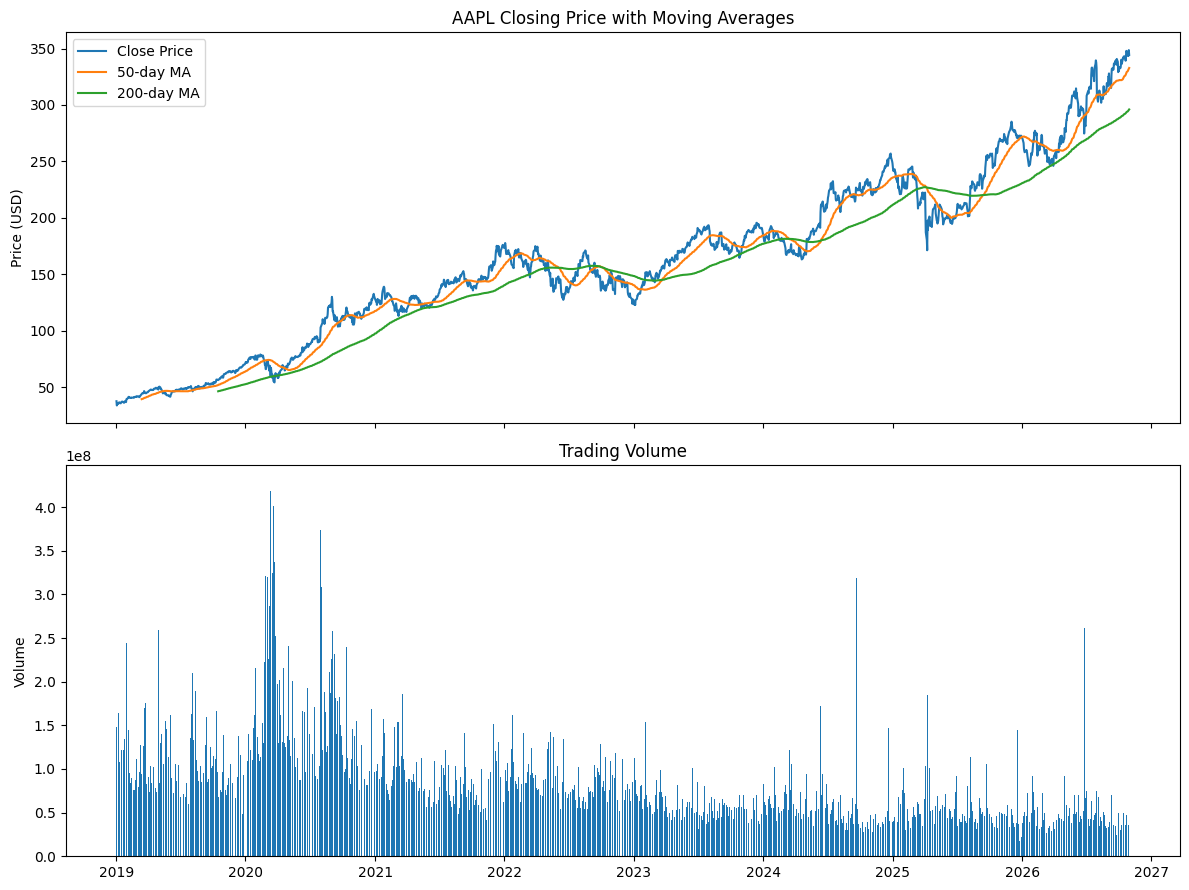

Highest close: 348.65 on 2026-10-29
Lowest close: 33.68 on 2019-01-03


In [5]:
df["MA50"] = df["Close"].rolling(50).mean()
df["MA200"] = df["Close"].rolling(200).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df.index, df["Close"], label="Close Price")
axes[0].plot(df.index, df["MA50"], label="50-day MA")
axes[0].plot(df.index, df["MA200"], label="200-day MA")
axes[0].set_title("AAPL Closing Price with Moving Averages")
axes[0].set_ylabel("Price (USD)")
axes[0].legend()

axes[1].bar(df.index, df["Volume"], width=1.0)
axes[1].set_title("Trading Volume")
axes[1].set_ylabel("Volume")

plt.tight_layout()
plt.savefig("finance_price_trend.png", dpi=150)
plt.show()

print("Highest close:", round(df["Close"].max(), 2), "on", df["Close"].idxmax().date())
print("Lowest close:", round(df["Close"].min(), 2), "on", df["Close"].idxmin().date())

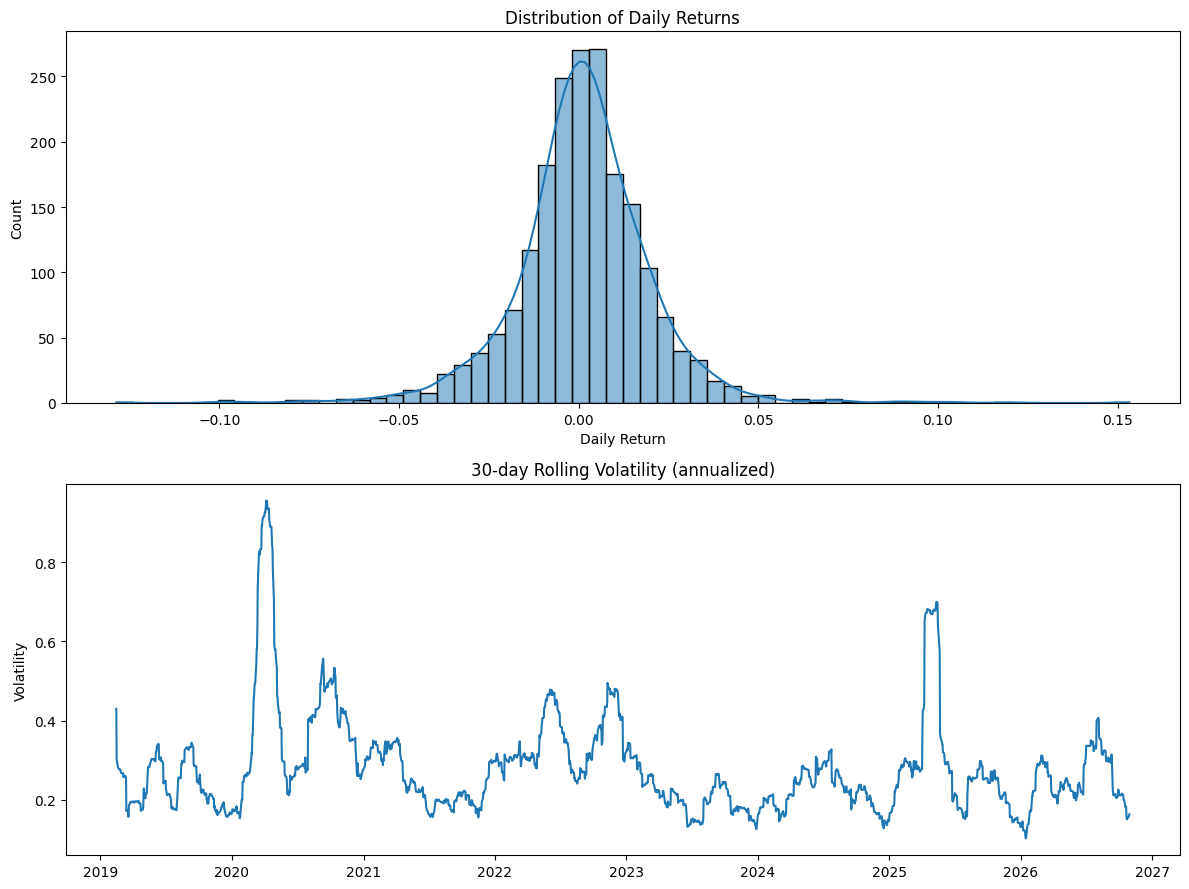

Average daily return (%): 0.131
Daily std deviation (%): 1.924
Best day (%): 15.33 on 2025-04-09
Worst day (%): -12.86 on 2020-03-16
Positive days (%): 53.8


In [6]:
df["Return"] = df["Close"].pct_change()
df["Volatility30"] = df["Return"].rolling(30).std() * np.sqrt(252)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

sns.histplot(df["Return"].dropna(), bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Daily Returns")
axes[0].set_xlabel("Daily Return")

axes[1].plot(df.index, df["Volatility30"])
axes[1].set_title("30-day Rolling Volatility (annualized)")
axes[1].set_ylabel("Volatility")

plt.tight_layout()
plt.savefig("finance_returns_volatility.png", dpi=150)
plt.show()

print("Average daily return (%):", round(df["Return"].mean() * 100, 3))
print("Daily std deviation (%):", round(df["Return"].std() * 100, 3))
print("Best day (%):", round(df["Return"].max() * 100, 2), "on", df["Return"].idxmax().date())
print("Worst day (%):", round(df["Return"].min() * 100, 2), "on", df["Return"].idxmin().date())
print("Positive days (%):", round((df["Return"] > 0).mean() * 100, 1))

Train rows: 1415 | Test rows: 354
Baseline accuracy: 0.5395

Logistic Regression accuracy: 0.5113
Random Forest accuracy: 0.5537


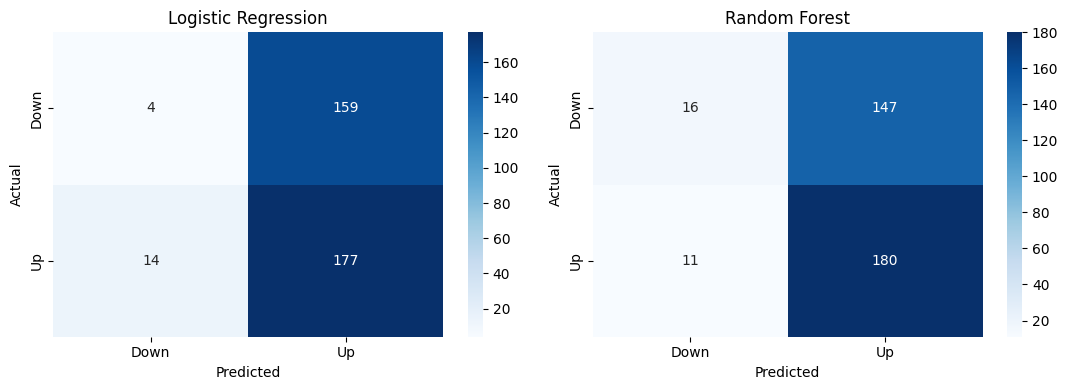


Random Forest report:
              precision    recall  f1-score   support

        Down       0.59      0.10      0.17       163
          Up       0.55      0.94      0.69       191

    accuracy                           0.55       354
   macro avg       0.57      0.52      0.43       354
weighted avg       0.57      0.55      0.45       354



In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Features
data = df.copy()
data["Return_lag1"] = data["Return"].shift(1)
data["Return_lag2"] = data["Return"].shift(2)
data["Return_lag3"] = data["Return"].shift(3)
data["MA_ratio"] = data["MA50"] / data["MA200"]
data["Price_to_MA50"] = data["Close"] / data["MA50"]
data["Volume_change"] = data["Volume"].pct_change()

# Target: 1 if next day's close is higher, else 0
data["Target"] = (data["Close"].shift(-1) > data["Close"]).astype(int)
data = data.iloc[:-1].dropna()

features = ["Return", "Return_lag1", "Return_lag2", "Return_lag3",
            "MA_ratio", "Price_to_MA50", "Volume_change"]

# Time-based split (first 80% train, last 20% test)
split = int(len(data) * 0.8)
X_train, X_test = data[features].iloc[:split], data[features].iloc[split:]
y_train, y_test = data["Target"].iloc[:split], data["Target"].iloc[split:]
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

# Baseline: always predict the most common class
baseline = max(y_test.mean(), 1 - y_test.mean())
print("Baseline accuracy:", round(baseline, 4))

# Models
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42).fit(X_train, y_train)

lr_pred = lr.predict(X_test_s)
rf_pred = rf.predict(X_test)

print("\nLogistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred), 4))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [lr_pred, rf_pred], ["Logistic Regression", "Random Forest"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Down", "Up"], yticklabels=["Down", "Up"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("finance_confusion_matrices.png", dpi=150)
plt.show()

print("\nRandom Forest report:")
print(classification_report(y_test, rf_pred, target_names=["Down", "Up"]))

In [8]:
print("Rows:", len(df))
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Highest close:", round(df["Close"].max(), 2), "on", df["Close"].idxmax().date())
print("Lowest close:", round(df["Close"].min(), 2), "on", df["Close"].idxmin().date())
print("Average daily return (%):", round(df["Return"].mean() * 100, 3))
print("Daily std deviation (%):", round(df["Return"].std() * 100, 3))
print("Best day (%):", round(df["Return"].max() * 100, 2), "on", df["Return"].idxmax().date())
print("Worst day (%):", round(df["Return"].min() * 100, 2), "on", df["Return"].idxmin().date())
print("Positive days (%):", round((df["Return"] > 0).mean() * 100, 1))
print("Baseline accuracy:", round(baseline, 4))
print("Logistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Test rows:", len(y_test))

imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("\nTop features (Random Forest):")
print(imp.round(3).head(4))

Rows: 1969
Date range: 2019-01-02 to 2026-10-30
Highest close: 348.65 on 2026-10-29
Lowest close: 33.68 on 2019-01-03
Average daily return (%): 0.131
Daily std deviation (%): 1.924
Best day (%): 15.33 on 2025-04-09
Worst day (%): -12.86 on 2020-03-16
Positive days (%): 53.8
Baseline accuracy: 0.5395
Logistic Regression accuracy: 0.5113
Random Forest accuracy: 0.5537
Test rows: 354

Top features (Random Forest):
Return         0.176
Return_lag1    0.145
MA_ratio       0.145
Return_lag3    0.143
dtype: float64
